In [1]:
from google.colab import files

uploaded = files.upload()

Saving dataset-ccn_project_trafficSignrecognation.zip to dataset-ccn_project_trafficSignrecognation.zip


In [2]:
import zipfile
import os

zip_files = [
    f for f in uploaded.keys()
    if f.lower().endswith(".zip")
]

assert len(zip_files) > 0, "No ZIP file uploaded!"

zip_path = "/content/" + zip_files[0]

extract_path = "/content/traffic_sign_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")
print("Extracted Location:", extract_path)

Dataset Extracted Successfully!
Extracted Location: /content/traffic_sign_dataset


In [3]:
import os

dataset_csv_path = None

for root, dirs, files_list in os.walk(extract_path):

    if "Train.csv" in files_list and "Test.csv" in files_list:

        dataset_csv_path = root
        break

assert dataset_csv_path is not None, "Train.csv or Test.csv not found!"

DATASET_PATH = dataset_csv_path

print("Dataset Folder:", DATASET_PATH)

print("Train.csv Exists:",
      os.path.exists(os.path.join(DATASET_PATH, "Train.csv")))

print("Test.csv Exists:",
      os.path.exists(os.path.join(DATASET_PATH, "Test.csv")))

print("Train Folder Exists:",
      os.path.isdir(os.path.join(DATASET_PATH, "Train")))

print("Test Folder Exists:",
      os.path.isdir(os.path.join(DATASET_PATH, "Test")))

Dataset Folder: /content/traffic_sign_dataset
Train.csv Exists: True
Test.csv Exists: True
Train Folder Exists: True
Test Folder Exists: True


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
import os
import re

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ReduceLROnPlateau

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("TensorFlow Version:", tf.__version__)

print("GPU Available:",
      len(tf.config.list_physical_devices("GPU")) > 0)

print("All Libraries Imported Successfully!")

TensorFlow Version: 2.21.0
GPU Available: True
All Libraries Imported Successfully!


In [5]:
train_df = pd.read_csv(
    os.path.join(DATASET_PATH, "Train.csv")
)

test_df = pd.read_csv(
    os.path.join(DATASET_PATH, "Test.csv")
)

signnames_df = pd.read_csv(
    os.path.join(DATASET_PATH, "signnames.csv")
)

print("Train Shape:", train_df.shape)

print("Test Shape:", test_df.shape)

print("Number of Classes:",
      train_df["ClassId"].nunique())

print("\nTrain Columns:")
print(train_df.columns.tolist())

print("\nFirst 5 Rows:")
print(train_df.head())

Train Shape: (39209, 8)
Test Shape: (12630, 8)
Number of Classes: 43

Train Columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

First 5 Rows:
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0     27      26       5       5      22      20       20   
1     28      27       5       6      23      22       20   
2     29      26       6       5      24      21       20   
3     28      27       5       6      23      22       20   
4     28      26       5       5      23      21       20   

                                   Path  
0  /code/Train/20/00020_00000_00000.png  
1  /code/Train/20/00020_00000_00001.png  
2  /code/Train/20/00020_00000_00002.png  
3  /code/Train/20/00020_00000_00003.png  
4  /code/Train/20/00020_00000_00004.png  


In [6]:
TRAIN_IMAGE_DIR = os.path.join(DATASET_PATH, "Train")

TEST_IMAGE_DIR = os.path.join(DATASET_PATH, "Test")


def correct_train_path(path):

    path = str(path).replace("\\", "/")

    match = re.search(r"(?:^|/)Train/(.+)$", path)

    if match:
        relative_path = match.group(1)
    else:
        relative_path = path

    return os.path.join(TRAIN_IMAGE_DIR, relative_path)


def correct_test_path(path):

    path = str(path).replace("\\", "/")

    match = re.search(r"(?:^|/)Test/(.+)$", path)

    if match:
        relative_path = match.group(1)
    else:
        relative_path = os.path.basename(path)

    return os.path.join(TEST_IMAGE_DIR, relative_path)


train_df["image_path"] = train_df["Path"].apply(
    correct_train_path
)

test_df["image_path"] = test_df["Path"].apply(
    correct_test_path
)


print("First Train Path:")
print(train_df["image_path"].iloc[0])

print("\nFirst Test Path:")
print(test_df["image_path"].iloc[0])

missing_train = sum(
    ~train_df["image_path"].apply(os.path.exists)
)

missing_test = sum(
    ~test_df["image_path"].apply(os.path.exists)
)

print("\nMissing Train Images:", missing_train)

print("Missing Test Images:", missing_test)

First Train Path:
/content/traffic_sign_dataset/Train/20/00020_00000_00000.png

First Test Path:
/content/traffic_sign_dataset/Test/00000.png

Missing Train Images: 0
Missing Test Images: 0


In [7]:
train_data, val_data = train_test_split(

    train_df,

    test_size=0.20,

    random_state=42,

    stratify=train_df["ClassId"]

)

print("Training Samples:", len(train_data))

print("Validation Samples:", len(val_data))

print("Testing Samples:", len(test_df))

Training Samples: 31367
Validation Samples: 7842
Testing Samples: 12630


In [8]:
IMG_SIZE = 128

BATCH_SIZE = 32

NUM_CLASSES = 43

EPOCHS = 30

LEARNING_RATE = 0.001

print("Image Size:", IMG_SIZE)

print("Batch Size:", BATCH_SIZE)

print("Number of Classes:", NUM_CLASSES)

print("Maximum Epochs:", EPOCHS)

print("Learning Rate:", LEARNING_RATE)

Image Size: 128
Batch Size: 32
Number of Classes: 43
Maximum Epochs: 30
Learning Rate: 0.001


In [9]:
def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_png(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [10]:
def create_dataset(dataframe, shuffle=False):

    paths = dataframe["image_path"].values

    labels = dataframe["ClassId"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:

        dataset = dataset.shuffle(
            buffer_size=10000,
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_dataset = create_dataset(
    train_data,
    shuffle=True
)

val_dataset = create_dataset(val_data)

test_dataset = create_dataset(test_df)


print("Training Dataset Created!")

print("Validation Dataset Created!")

print("Testing Dataset Created!")

Training Dataset Created!
Validation Dataset Created!
Testing Dataset Created!


In [11]:
for images, labels in train_dataset.take(1):

    print("Image Batch Shape:", images.shape)

    print("Label Batch Shape:", labels.shape)

    print("Minimum Pixel Value:",
          tf.reduce_min(images).numpy())

    print("Maximum Pixel Value:",
          tf.reduce_max(images).numpy())

Image Batch Shape: (32, 128, 128, 3)
Label Batch Shape: (32,)
Minimum Pixel Value: 0.00058210787
Maximum Pixel Value: 1.0


In [12]:
data_augmentation = tf.keras.Sequential([

    layers.RandomRotation(0.03),

    layers.RandomZoom(0.10),

    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )

], name="data_augmentation")


print("Data Augmentation Created Successfully!")

data_augmentation.summary()

Data Augmentation Created Successfully!


Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [13]:
model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    # Data Augmentation
    data_augmentation,

    # Convolution Block 1
    layers.Conv2D(
        32,
        (3, 3),
        padding="same"
    ),

    layers.BatchNormalization(),

    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(
        64,
        (3, 3),
        padding="same"
    ),

    layers.BatchNormalization(),

    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(
        128,
        (3, 3),
        padding="same"
    ),

    layers.BatchNormalization(),

    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),

    # Fully Connected Layers
    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    # Dropout to reduce overfitting
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )

])

print("Basic Custom CNN Created Successfully!")

Basic Custom CNN Created Successfully!


In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,294,123 (16.38 MB)

 Trainable params: 4,293,675 (16.38 MB)

 Non-trainable params: 448 (1.75 KB)

In [15]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [16]:
class MinimumEpochEarlyStopping(tf.keras.callbacks.Callback):

    def __init__(self, patience=5, min_epochs=5):

        super().__init__()

        self.patience = patience

        self.min_epochs = min_epochs

        self.best = float("inf")

        self.wait = 0

        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):

        current = logs.get("val_loss")

        if current is None:
            return

        if current < self.best:

            self.best = current

            self.wait = 0

            self.best_weights = self.model.get_weights()

        else:

            if epoch + 1 >= self.min_epochs:

                self.wait += 1

        if (
            epoch + 1 >= self.min_epochs
            and self.wait >= self.patience
        ):

            print("Early Stopping Triggered!")

            self.model.stop_training = True

    def on_train_end(self, logs=None):

        if self.best_weights is not None:

            self.model.set_weights(
                self.best_weights
            )


early_stopping = MinimumEpochEarlyStopping(
    patience=5,
    min_epochs=5
)


reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=2,

    min_lr=0.00001,

    verbose=1

)


print("Early Stopping Ready!")

print("Learning Rate Reduction Ready!")

Early Stopping Ready!
Learning Rate Reduction Ready!


In [17]:
history = model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=EPOCHS,

    callbacks=[
        early_stopping,
        reduce_lr
    ]

)

Epoch 1/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 62s 54ms/step - accuracy: 0.0548 - loss: 3.7116 - val_accuracy: 0.0574 - val_loss: 3.5504 - learning_rate: 0.0010
Epoch 2/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 49s 50ms/step - accuracy: 0.0574 - loss: 3.5200 - val_accuracy: 0.0574 - val_loss: 3.5007 - learning_rate: 0.0010
Epoch 3/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 49s 50ms/step - accuracy: 0.0574 - loss: 3.4942 - val_accuracy: 0.0574 - val_loss: 3.4894 - learning_rate: 0.0010
Epoch 4/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 51s 52ms/step - accuracy: 0.0565 - loss: 3.4882 - val_accuracy: 0.0574 - val_loss: 3.4867 - learning_rate: 0.0010
Epoch 5/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 50s 50ms/step - accuracy: 0.0571 - loss: 3.4866 - val_accuracy: 0.0574 - val_loss: 3.4859 - learning_rate: 0.0010
Epoch 6/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 50s 51ms/step - accuracy: 0.0570 - loss: 3.4862 - val_accuracy: 0.0574 - val_loss: 3.4856 - learning_rate: 0.0010
Epoch 7/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 83s 53ms/step - accuracy: 0.0567 - l

In [18]:
print("Total Epochs Trained:",
      len(history.history["loss"]))

print("Best Validation Accuracy:",
      max(history.history["val_accuracy"]))

print("Best Validation Loss:",
      min(history.history["val_loss"]))

Total Epochs Trained: 25
Best Validation Accuracy: 0.05738332122564316
Best Validation Loss: 3.485459804534912


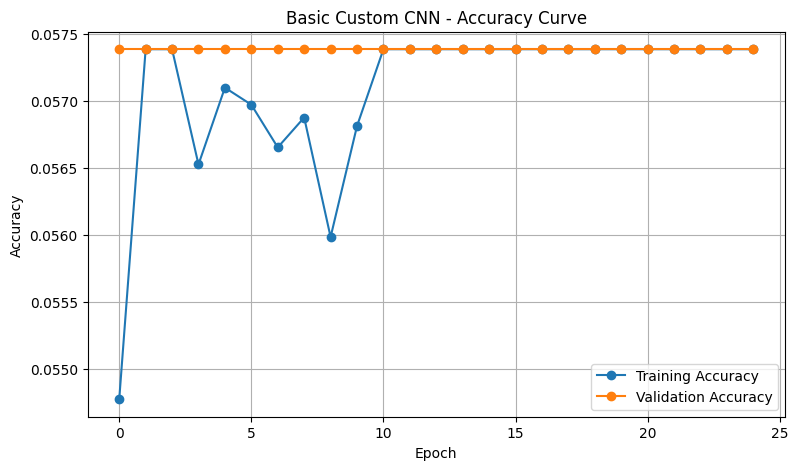

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Basic Custom CNN - Accuracy Curve")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.savefig(
    "/content/person1_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

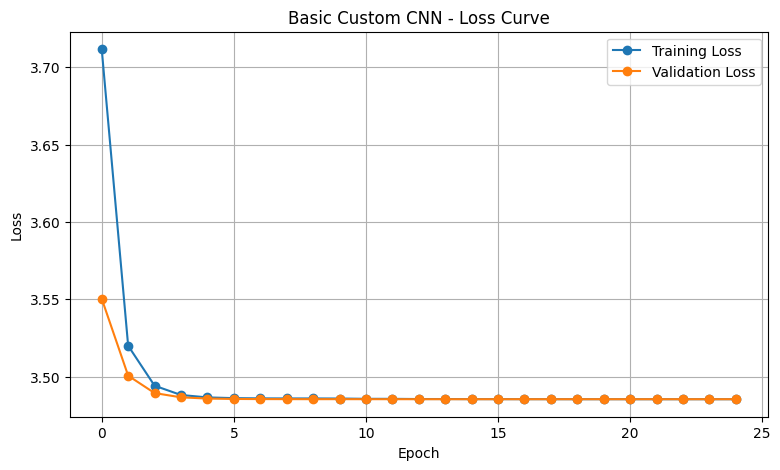

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Basic Custom CNN - Loss Curve")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.savefig(
    "/content/person1_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
test_loss, test_accuracy = model.evaluate(
    test_dataset
)

print("\n========== TEST RESULTS ==========")

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

print(
    "Test Accuracy Percentage:",
    test_accuracy * 100
)

print("==================================")

395/395 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.0594 - loss: 3.4628

========== TEST RESULTS ==========
Test Loss: 3.4627792835235596
Test Accuracy: 0.059382423758506775
Test Accuracy Percentage: 5.9382423758506775


In [22]:
y_true = test_df["ClassId"].values

y_pred_prob = model.predict(test_dataset)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Prediction Completed!")

print("Total Predictions:", len(y_pred))

395/395 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step
Prediction Completed!
Total Predictions: 12630


In [23]:
target_names = (
    signnames_df
    .sort_values("ClassId")["SignName"]
    .tolist()
)

report = classification_report(

    y_true,

    y_pred,

    labels=list(range(NUM_CLASSES)),

    target_names=target_names,

    zero_division=0

)

print("========== CLASSIFICATION REPORT ==========")

print(report)

========== CLASSIFICATION REPORT ==========
                                                    precision    recall  f1-score   support

                              Speed limit (20km/h)       0.00      0.00      0.00        60
                              Speed limit (30km/h)       0.00      0.00      0.00       720
                              Speed limit (50km/h)       0.06      1.00      0.11       750
                              Speed limit (60km/h)       0.00      0.00      0.00       450
                              Speed limit (70km/h)       0.00      0.00      0.00       660
                              Speed limit (80km/h)       0.00      0.00      0.00       630
                       End of speed limit (80km/h)       0.00      0.00      0.00       150
                             Speed limit (100km/h)       0.00      0.00      0.00       450
                             Speed limit (120km/h)       0.00      0.00      0.00       450
                                   

In [24]:
with open(
    "/content/person1_classification_report.txt",
    "w"
) as f:

    f.write(report)

print("Classification Report Saved!")

Classification Report Saved!


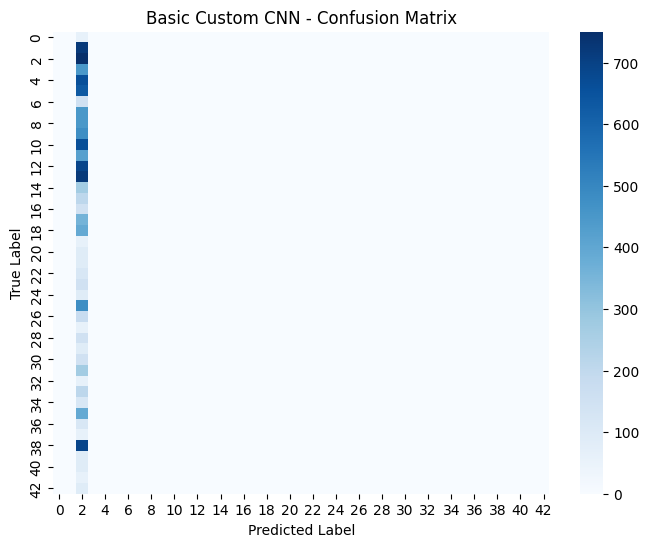

In [26]:
cm = confusion_matrix(

    y_true,

    y_pred,

    labels=list(range(NUM_CLASSES))

)

plt.figure(figsize=(8, 6))

sns.heatmap(

    cm,

    cmap="Blues",

    annot=False,

    fmt="d"

)

plt.title(
    "Basic Custom CNN - Confusion Matrix"
)

plt.xlabel("Predicted Label")

plt.ylabel("True Label")

plt.savefig(
    "/content/person1_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()